In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
from sklearn import linear_model
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder

In [2]:
data = pd.read_csv("/content/drive/MyDrive/Lab_01_Python_Libraries/E-commerce Customer Behavior - Sheet1.csv")
data.head()

,Customer ID,Gender,Age,City,Membership Type,Total Spend,Items Purchased,Average Rating,Discount Applied,Days Since Last Purchase,Satisfaction Level
0,101,Female,29,New York,Gold,1120.20,14,4.6,True,25,Satisfied
1,102,Male,34,Los Angeles,Silver,780.50,11,4.1,False,18,Neutral
2,103,Female,43,Chicago,Bronze,510.75,9,3.4,True,42,Unsatisfied
3,104,Male,30,San Francisco,Gold,1480.30,19,4.7,False,12,Satisfied
4,105,Male,27,Miami,Silver,720.40,13,4.0,True,55,Unsatisfied


In [3]:
data.drop(columns = ["Customer ID"], inplace = True)

In [4]:
data.shape

(350, 10)

In [5]:
data.isna().sum()

,0
Gender,0
Age,0
City,0
Membership Type,0
Total Spend,0
Items Purchased,0
Average Rating,0
Discount Applied,0
Days Since Last Purchase,0
Satisfaction Level,2


In [6]:
df =  data

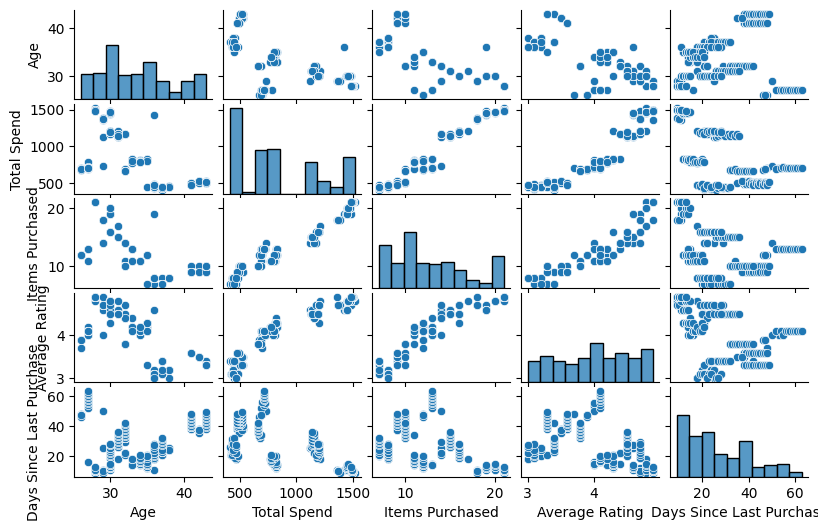

In [7]:
g = sns.pairplot(df.select_dtypes(include=np.number))
g.fig.set_size_inches(8,5)
plt.show()


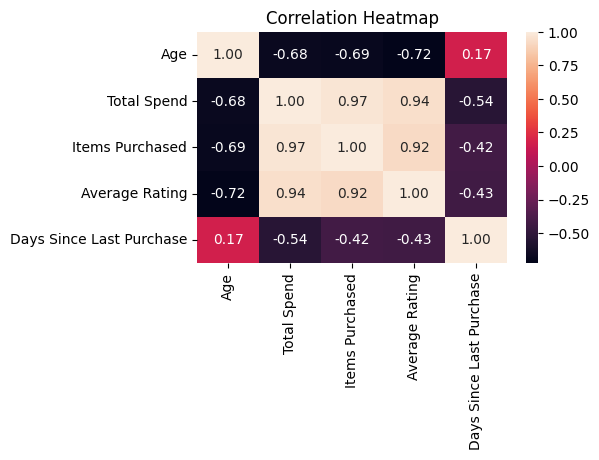

In [8]:
plt.figure(figsize=(5,3))
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

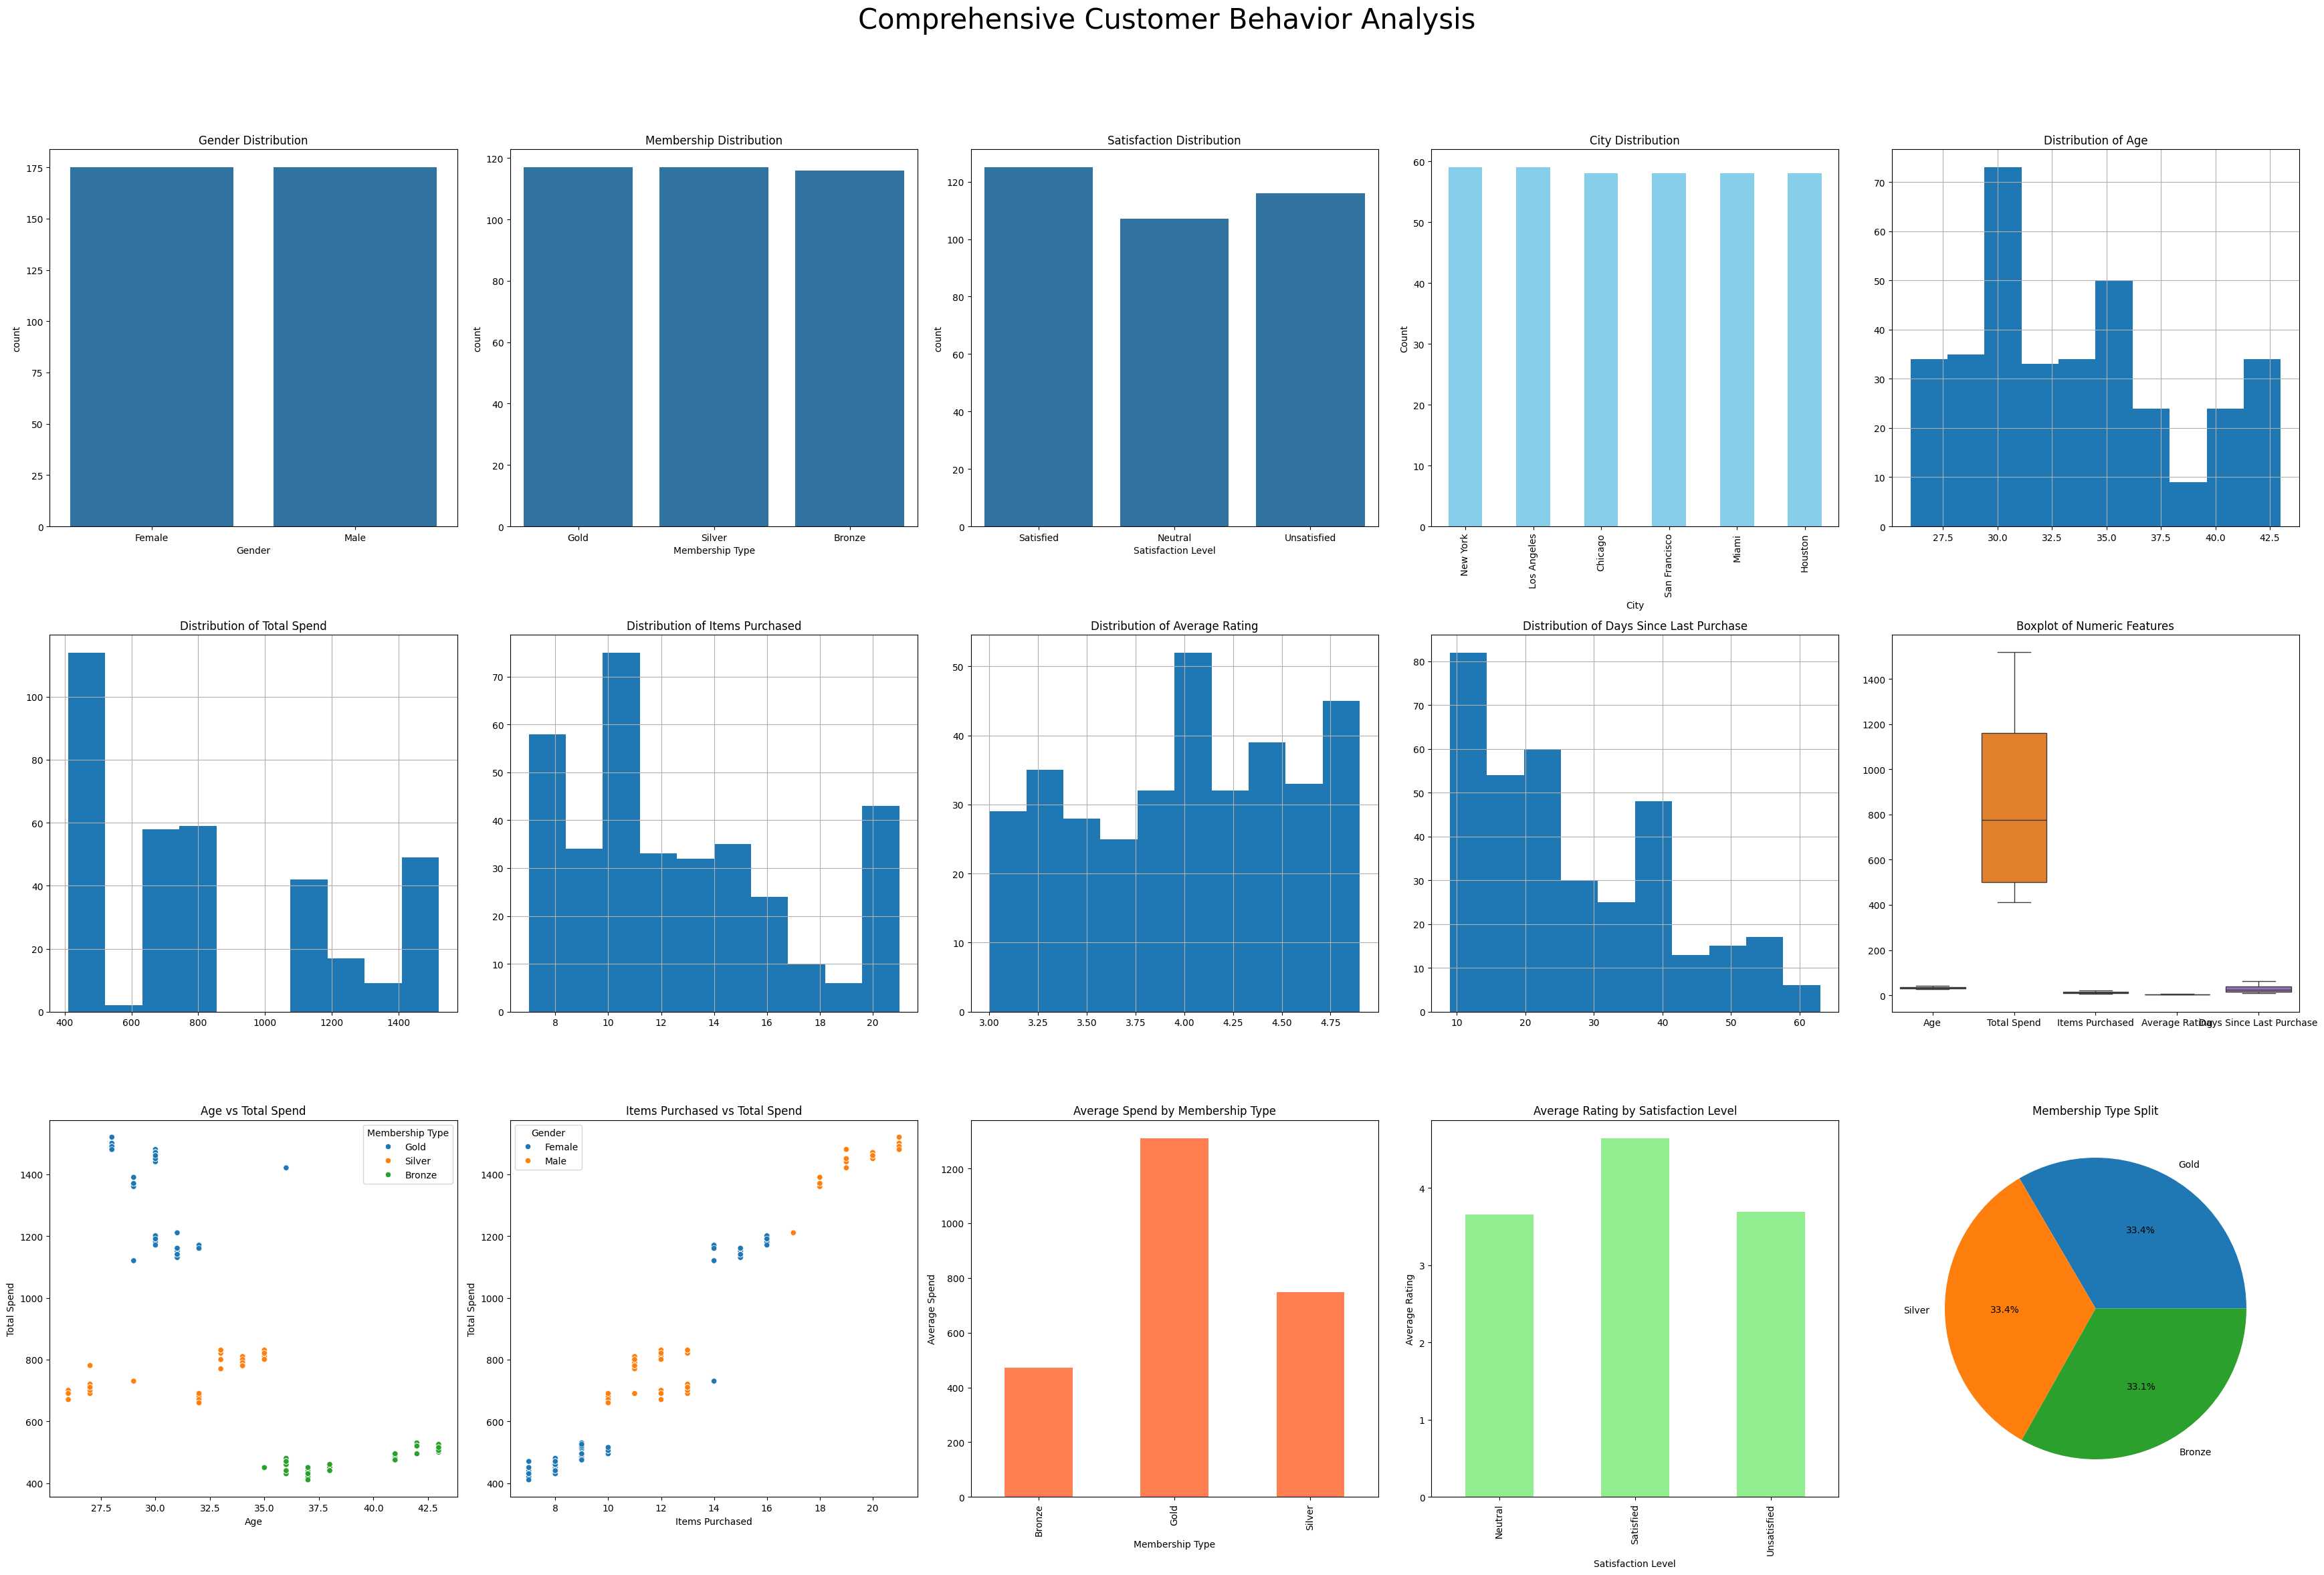

In [10]:
fig, axes = plt.subplots(nrows=4, ncols=5, figsize=(35, 30))
axes = axes.flatten()
ax_idx = 0

sns.countplot(x="Gender", data=df, ax=axes[ax_idx])
axes[ax_idx].set_title("Gender Distribution")
ax_idx += 1

sns.countplot(x="Membership Type", data=df, ax=axes[ax_idx])
axes[ax_idx].set_title("Membership Distribution")
ax_idx += 1

sns.countplot(x="Satisfaction Level", data=df, ax=axes[ax_idx])
axes[ax_idx].set_title("Satisfaction Distribution")
ax_idx += 1

df["City"].value_counts().plot(kind="bar", color="skyblue", ax=axes[ax_idx])
axes[ax_idx].set_title("City Distribution")
axes[ax_idx].set_ylabel("Count")
ax_idx += 1

numerical_cols = df.select_dtypes(include=np.number).columns
for col in numerical_cols:
    df[col].hist(ax=axes[ax_idx], bins=10)
    axes[ax_idx].set_title(f"Distribution of {col}")
    ax_idx += 1

sns.boxplot(data=df.select_dtypes(include=np.number), ax=axes[ax_idx])
axes[ax_idx].set_title("Boxplot of Numeric Features")
ax_idx += 1

sns.scatterplot(x="Age", y="Total Spend", hue="Membership Type", data=df, ax=axes[ax_idx])
axes[ax_idx].set_title("Age vs Total Spend")
ax_idx += 1

sns.scatterplot(x="Items Purchased", y="Total Spend", hue="Gender", data=df, ax=axes[ax_idx])
axes[ax_idx].set_title("Items Purchased vs Total Spend")
ax_idx += 1

df.groupby("Membership Type")["Total Spend"].mean().plot(kind="bar", color="coral", ax=axes[ax_idx])
axes[ax_idx].set_title("Average Spend by Membership Type")
axes[ax_idx].set_ylabel("Average Spend")
ax_idx += 1

df.groupby("Satisfaction Level")["Average Rating"].mean().plot(kind="bar", color="lightgreen", ax=axes[ax_idx])
axes[ax_idx].set_title("Average Rating by Satisfaction Level")
axes[ax_idx].set_ylabel("Average Rating")
ax_idx += 1

df["Membership Type"].value_counts().plot(kind="pie", autopct="%1.1f%%", ax=axes[ax_idx])
axes[ax_idx].set_title("Membership Type Split")
axes[ax_idx].set_ylabel("")
ax_idx += 1

for i in range(ax_idx, len(axes)):
    fig.delaxes(axes[i])

plt.suptitle("Comprehensive Customer Behavior Analysis", fontsize=30, y=1.02)
plt.tight_layout(rect=[0, 0.03, 1, 0.98])
plt.show()


In [11]:
data.dropna(inplace = True)

In [12]:
X = data.drop(columns = ["Satisfaction Level"])
y = data["Satisfaction Level"]

In [13]:
str_col = X.select_dtypes(include=["object", "string"]).columns
num_col = X.select_dtypes(include=["int64", "double", "float"]).columns
str_col, num_col, X.columns

(Index(['Gender', 'City', 'Membership Type'], dtype='object'),
 Index(['Age', 'Total Spend', 'Items Purchased', 'Average Rating',
        'Days Since Last Purchase'],
       dtype='object'),
 Index(['Gender', 'Age', 'City', 'Membership Type', 'Total Spend',
        'Items Purchased', 'Average Rating', 'Discount Applied',
        'Days Since Last Purchase'],
       dtype='object'))

In [14]:
df1 = pd.DataFrame()
scaler = MinMaxScaler()
df1[num_col] = scaler.fit_transform(X[num_col])
df1

,Age,Total Spend,Items Purchased,Average Rating,Days Since Last Purchase
0,0.176471,0.639502,0.500000,0.842105,0.296296
1,0.470588,0.333273,0.285714,0.578947,0.166667
2,1.000000,0.090102,0.142857,0.210526,0.611111
3,0.235294,0.964122,0.857143,0.894737,0.055556
4,0.058824,0.279095,0.428571,0.526316,0.851852
...,...,...,...,...,...
343,0.352941,0.224917,0.214286,0.421053,0.611111
344,0.588235,0.053818,0.071429,0.000000,0.333333
345,0.235294,0.703146,0.642857,0.789474,0.351852
346,0.470588,0.333003,0.285714,0.631579,0.222222


In [15]:
gen_le = LabelEncoder()
city_le = LabelEncoder()
ship_le = LabelEncoder()

df1["Gender"] = gen_le.fit_transform(X["Gender"])
df1["City"] = city_le.fit_transform(X["City"])
df1["Membership Type"] = ship_le.fit_transform(X["Membership Type"])
df1

,Age,Total Spend,Items Purchased,Average Rating,Days Since Last Purchase,Gender,City,Membership Type
0,0.176471,0.639502,0.500000,0.842105,0.296296,0,4,1
1,0.470588,0.333273,0.285714,0.578947,0.166667,1,2,2
2,1.000000,0.090102,0.142857,0.210526,0.611111,0,0,0
3,0.235294,0.964122,0.857143,0.894737,0.055556,1,5,1
4,0.058824,0.279095,0.428571,0.526316,0.851852,1,3,2
...,...,...,...,...,...,...,...,...
343,0.352941,0.224917,0.214286,0.421053,0.611111,1,3,2
344,0.588235,0.053818,0.071429,0.000000,0.333333,0,1,0
345,0.235294,0.703146,0.642857,0.789474,0.351852,0,4,1
346,0.470588,0.333003,0.285714,0.631579,0.222222,1,2,2


In [16]:
df1.shape

(348, 8)

In [17]:
df1.fillna(df1.mean(), inplace = True)
df1.isna().sum()

,0
Age,0
Total Spend,0
Items Purchased,0
Average Rating,0
Days Since Last Purchase,0
Gender,0
City,0
Membership Type,0


In [18]:
y_le = LabelEncoder()
y = y_le.fit_transform(y)
print("Original unique values of 'Satisfaction Level':", data["Satisfaction Level"].unique())

# Create a dictionary to show the mapping
satisfaction_level_mapping = dict(zip(y_le.transform(y_le.classes_), y_le.classes_))
print("\nMapping of encoded values to original labels:", satisfaction_level_mapping)

Original unique values of 'Satisfaction Level': ['Satisfied' 'Neutral' 'Unsatisfied']

Mapping of encoded values to original labels: {np.int64(0): 'Neutral', np.int64(1): 'Satisfied', np.int64(2): 'Unsatisfied'}


In [19]:
df1.shape , y.shape

((348, 8), (348,))

In [20]:
linear_model = linear_model.LinearRegression()
logistic_model = LogisticRegression()
decision_model = DecisionTreeClassifier()
random_model = RandomForestClassifier()
svm_model = SVC()
knn_model = KNeighborsClassifier(n_neighbors = 3)
naive_model = GaussianNB()

In [21]:
X_train, X_test, y_train, y_test = train_test_split(df1, y, test_size = 0.2)

In [22]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((278, 8), (70, 8), (278,), (70,))

In [23]:
X_test.head(2)

,Age,Total Spend,Items Purchased,Average Rating,Days Since Last Purchase,Gender,City,Membership Type
143,0.529412,0.369693,0.357143,0.684211,0.055556,1,2,2
61,0.411765,0.378572,0.428571,0.631579,0.092593,1,2,2


In [24]:
logistic_model = logistic_model.fit(X_train, y_train)
y_pred = logistic_model.predict(X_test)
accuracy_score(y_test, y_pred)

0.9714285714285714

In [25]:
decision_model = decision_model.fit(X_train, y_train)
y_pred = decision_model.predict(X_test)
accuracy_score(y_test, y_pred)

1.0

In [26]:
random_model = random_model.fit(X_train, y_train)
y_pred = random_model.predict(X_test)
accuracy_score(y_test, y_pred)

1.0

In [27]:
svm_model = svm_model.fit(X_train, y_train)
y_pred = svm_model.predict(X_test)
accuracy_score(y_test, y_pred)

0.9714285714285714

In [28]:
knn_model = knn_model.fit(X_train, y_train)
y_pred = knn_model.predict(X_test)
accuracy_score(y_test, y_pred)

1.0

In [29]:
naive_model = naive_model.fit(X_train, y_train)
y_pred = naive_model.predict(X_test)
accuracy_score(y_test, y_pred)

0.9714285714285714

In [30]:
logistic_accuracy = accuracy_score(y_test, logistic_model.predict(X_test))
decision_accuracy = accuracy_score(y_test, decision_model.predict(X_test))
random_accuracy = accuracy_score(y_test, random_model.predict(X_test))
svm_accuracy = accuracy_score(y_test, svm_model.predict(X_test))
knn_accuracy = accuracy_score(y_test, knn_model.predict(X_test))
naive_accuracy = accuracy_score(y_test, naive_model.predict(X_test))

accuracy_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest', 'SVM', 'KNN', 'Naive Bayes'],
    'Accuracy': [logistic_accuracy, decision_accuracy, random_accuracy, svm_accuracy, knn_accuracy, naive_accuracy]
})


In [31]:
cities = data["City"].tolist()
cities = list(set(cities))
with open("/content/drive/MyDrive/Lab_01_Python_Libraries/cities.json", "w") as f:
  json.dump(cities, f)

In [32]:
joblib.dump(knn_model, "/content/drive/MyDrive/Lab_01_Python_Libraries/final_model.pkl")
joblib.dump(y_le, "/content/drive/MyDrive/Lab_01_Python_Libraries/y_le.pkl")
joblib.dump(gen_le, "/content/drive/MyDrive/Lab_01_Python_Libraries/eng_le.pkl")
joblib.dump(city_le, "/content/drive/MyDrive/Lab_01_Python_Libraries/city_le.pkl")
joblib.dump(ship_le, "/content/drive/MyDrive/Lab_01_Python_Libraries/ship_le.pkl")
joblib.dump(scaler, "/content/drive/MyDrive/Lab_01_Python_Libraries/scaler.pkl")

['/content/drive/MyDrive/Lab_01_Python_Libraries/scaler.pkl']

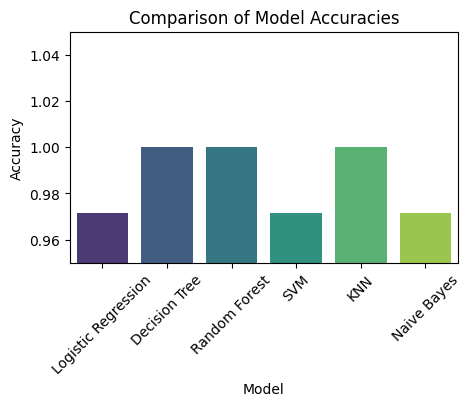

In [33]:
plt.figure(figsize=(5, 3))
plt.xticks(rotation=45)
sns.barplot(x='Model', y='Accuracy', hue='Model', data=accuracy_df, palette='viridis', legend=False)
plt.title('Comparison of Model Accuracies')
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.ylim(0.95, 1.05)
plt.show()

In [39]:
def predict(model, new_customer_data_dict, scaler, gen_le, city_le, ship_le, y_le, df1_columns_order):
  new_customer_df = pd.DataFrame([new_customer_data_dict])
  processed_customer_df = new_customer_df.copy()

  # Numerical columns to scale
  num_cols_for_prediction = ['Age', 'Total Spend', 'Items Purchased', 'Average Rating', 'Days Since Last Purchase']
  processed_customer_df[num_cols_for_prediction] = scaler.transform(processed_customer_df[num_cols_for_prediction])

  # Categorical columns to encode
  processed_customer_df['Gender'] = gen_le.transform(processed_customer_df['Gender'])
  processed_customer_df['City'] = city_le.transform(processed_customer_df['City'])
  processed_customer_df['Membership Type'] = ship_le.transform(processed_customer_df['Membership Type'])

  # Reorder columns to match df1
  processed_customer_df = processed_customer_df[df1_columns_order]


  predicted_satisfaction_encoded = model.predict(processed_customer_df)
  predicted_satisfaction_level = y_le.inverse_transform(predicted_satisfaction_encoded)

  print("Predicted Satisfaction Level for the new customer:", predicted_satisfaction_level[0])




new_customer_data = {
    'Age': 32,
    'Gender': 'Male',
    'City': 'Los Angeles',
    'Membership Type': 'Silver',
    'Total Spend': 1045.60,
    'Items Purchased': 15,
    'Average Rating': 4.4,
    'Days Since Last Purchase': 22,
    'Discount Applied': False
  }

# Get the column order from df1 (our training data) to ensure consistency
df1_columns_order = df1.columns.tolist()

# Call the refactored predict function
predict(random_model, new_customer_data, scaler, gen_le, city_le, ship_le, y_le, df1_columns_order)

Predicted Satisfaction Level for the new customer: Satisfied
